In [94]:
import matplotlib.pyplot as plt
import numpy as np

from challenge.dataset import Dataset, yolo_to_xyxy
from challenge.metrics import (
    avg_proposals_per_image,
    evaluate_miss_rate,
    evaluate_proposal_recall,
    evaluate_soft_proposal_recall,
)
from challenge.models import FeatureBuilder, FeatureConfig
from challenge.visuals import (
    add_yolo_boxes,
    plot_image_with_boxes,
    print_proposal_metrics,
    names,
)
import cv2

In [95]:
seed = 42

rng = np.random.default_rng(seed)

cfg = FeatureConfig(
    min_area_rel=0.0001,  # permissive
    min_edge_density=0.0,  # irrelevant now
    use_mser=True,
    mser_min_area_rel=0.0008,  # best efficiency
    mser_max_area_rel=0.25,  # best recall
    dedup_iou_thresh=0.40,  # good trade-off
)

In [96]:
train_data = Dataset("../data/data_notebook.yaml", split="train")
val_data = Dataset("../data/data_notebook.yaml", split="val")

In [97]:
## Create small dataset for illustration
idx = rng.integers(low=0, high=len(train_data), size=100)
tiny_data = [train_data[i] for i in idx]

In [98]:
model = FeatureBuilder(cfg)

In [99]:
X, y = model.build_training_set(tiny_data)

  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [00:10<00:00,  9.19it/s]


In [100]:
bboxes = model.propose_boxes(tiny_data)
bboxes = model.assign_labels(tiny_data, bboxes)
patches = []
for i, sample in enumerate(tiny_data):
    img = sample["image"]
    H, W = img.shape[:2]
    _, boxes_xyxy = yolo_to_xyxy(bboxes[i], H, W)
    for idx, (x1, y1, x2, y2) in enumerate(boxes_xyxy):
        ix1, iy1 = max(0, round(x1)), max(0, round(y1))
        ix2, iy2 = min(W, round(x2)), min(H, round(y2))
        patch = img[iy1:iy2, ix1:ix2]
        patches.append(cv2.resize(patch, (64, 64)))
patches = np.array(patches)
patches.shape

(3697, 64, 64, 3)

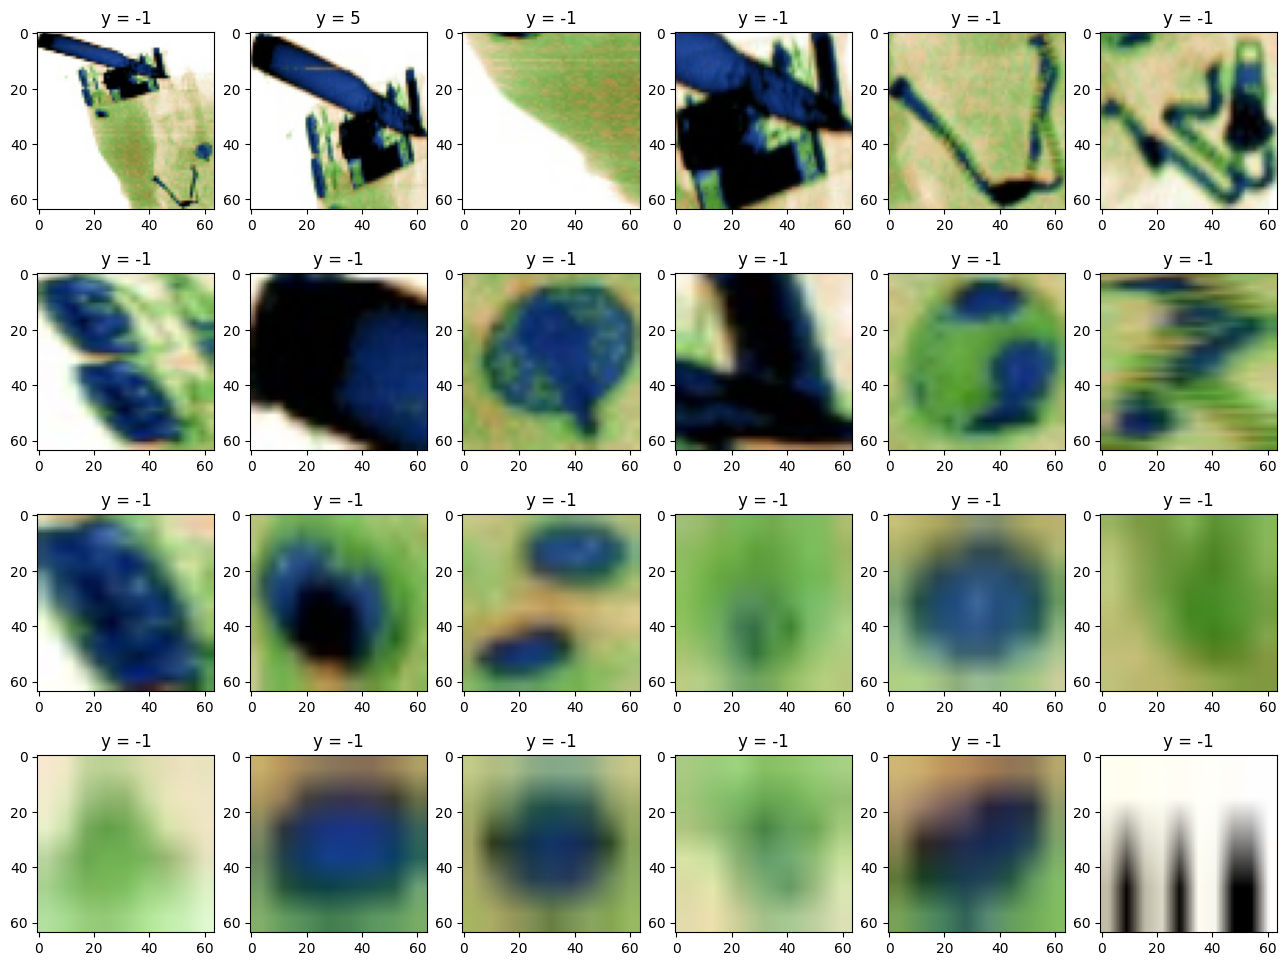

In [101]:
fig, ax = plt.subplots(4, 6, figsize=(16, 12))
ax = ax.flatten()
for i in range(24):
    ax[i].imshow(patches[i])
    ax[i].set_title(f"y = {y[i]}")


In [102]:
print("X shape:", X.shape)
print("y shape:", y.shape)

unique, counts = np.unique(y, return_counts=True)
print("Label distribution:")
for u, c in zip(unique, counts):
    print(f"  label {u:2d}: {c}")


X shape: (3697, 1764)
y shape: (3697,)
Label distribution:
  label -1: 3562
  label  0: 20
  label  1: 15
  label  2: 29
  label  3: 18
  label  4: 24
  label  5: 29


In [103]:
print("Feature stats:")
print("  mean:", X.mean())
print("  std :", X.std())
print("  min :", X.min())
print("  max :", X.max())


Feature stats:
  mean: 0.11771745
  std : 0.11791114
  min : 0.0
  max : 1.0


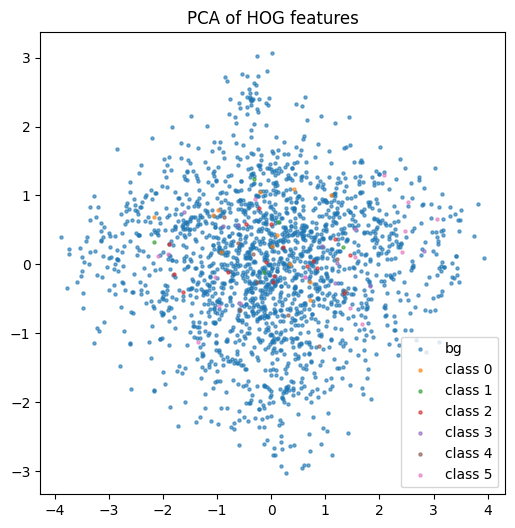

In [104]:
from sklearn.decomposition import PCA


def plot_pca(X, y, n=2000):
    idx = np.random.choice(len(X), min(n, len(X)), replace=False)
    Xs, ys = X[idx], y[idx]

    pca = PCA(n_components=2)
    Z = pca.fit_transform(Xs)

    plt.figure(figsize=(6, 6))
    for cls in np.unique(ys):
        mask = ys == cls
        label = "bg" if cls == -1 else f"class {cls}"
        plt.scatter(Z[mask, 0], Z[mask, 1], s=5, label=label, alpha=0.6)
    plt.legend()
    plt.title("PCA of HOG features")


plot_pca(X, y)


In [105]:
y.shape, patches.shape

((3697,), (3697, 64, 64, 3))

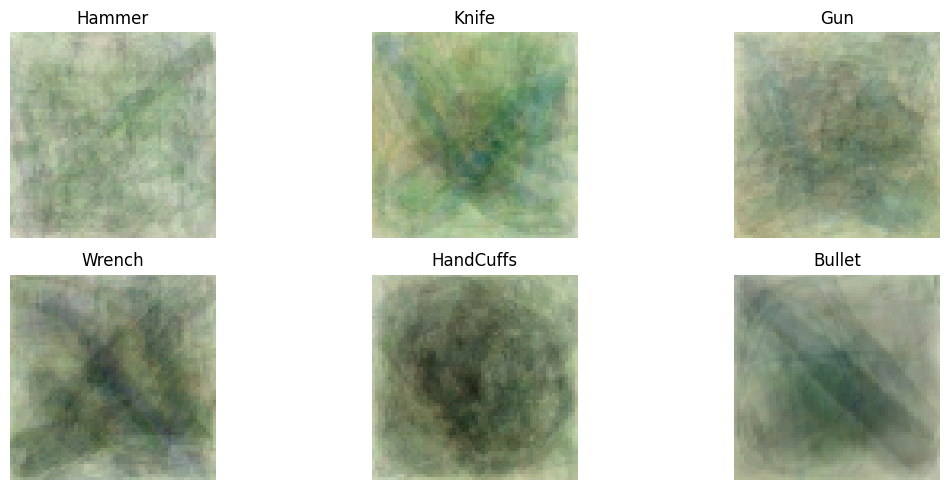

In [107]:
fig, axs = plt.subplots(2, 3, figsize=(12, 5))

axs = axs.flatten()
for i, ax in enumerate(axs):
    ax.imshow(patches[y == i].mean(axis=0).astype(np.uint))
    ax.set_title(f"{names[i]}")
    ax.axis("off")
plt.tight_layout()

In [123]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

clf = make_pipeline(StandardScaler(), LinearSVC(random_state=seed))
clf.fit(X, y)

KeyboardInterrupt: 